Análise do relatório de doenças por procedência

In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px

In [2]:
df_dp = pd.read_csv('C:/Users/thami/OneDrive/Documentos/Unitoledo/Pesquisa e produtividade/dados/relatorio de doenças por procedencia.csv', 
                 sep=None,          # Let pandas detect the separator
                 engine='python',   # Use the python engine which is more flexible
                 encoding='utf-8',  # Specify encoding to handle special characters
                 on_bad_lines='warn')  # Use on_bad_lines instead of error_bad_lines
print(df_dp.head())

   MES_ANO UF_PROCEDENCIA  ESPECIE            DIAGNOSTICO  \
0  01/2003             PA  Bovinos                Bursite   
1  01/2004             RS   Suinos               Pleurite   
2  01/2005             SC     Aves             Septicemia   
3  01/2006             SP     Aves  Evisceracao Retardada   
4  01/2007             PE     Aves           Colibacilose   

   NUMERO_ANIMAIS_ACOMETIDOS  
0                        6.0  
1                       17.0  
2                      292.0  
3                       21.0  
4                       15.0  


In [3]:
#analisando o formato das colunas
df_dp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   MES_ANO                    244948 non-null  object 
 1   UF_PROCEDENCIA             244948 non-null  object 
 2   ESPECIE                    244948 non-null  object 
 3   DIAGNOSTICO                244948 non-null  object 
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  float64
dtypes: float64(1), object(4)
memory usage: 9.3+ MB


In [4]:
#analisando a estatística básica
pd.set_option('display.float_format', '{:.0f}'.format) #0f é para sem casa decimal
print(df_dp.describe())

       NUMERO_ANIMAIS_ACOMETIDOS
count                     244948
mean                       15438
std                       123208
min                            0
25%                            4
50%                           44
75%                          966
max                      5733671


In [5]:
#identificar colunas com not a number (NaN)
df_dp.isna().sum()
#identificar linhas que contenham algum not a number (NaN)
df_dp[df_dp.isna().any(axis=1)]

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS


In [6]:
#verifica a quantidade de informados 0
df_dp_0 = (df_dp == 0).sum()
print(df_dp_0)

MES_ANO                        0
UF_PROCEDENCIA                 0
ESPECIE                        0
DIAGNOSTICO                    0
NUMERO_ANIMAIS_ACOMETIDOS    371
dtype: int64


In [7]:
#analisa para encontrar linhas duplicadas
duplicate_dp = df_dp[df_dp.duplicated()]
print(duplicate_dp) #resultado sem linhas duplicadas

Empty DataFrame
Columns: [MES_ANO, UF_PROCEDENCIA, ESPECIE, DIAGNOSTICO, NUMERO_ANIMAIS_ACOMETIDOS]
Index: []


In [8]:
df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] = df_dp['NUMERO_ANIMAIS_ACOMETIDOS'].astype(int)
print(df_dp.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   MES_ANO                    244948 non-null  object
 1   UF_PROCEDENCIA             244948 non-null  object
 2   ESPECIE                    244948 non-null  object
 3   DIAGNOSTICO                244948 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 9.3+ MB
None


In [9]:
df_dp.nunique()

MES_ANO                        309
UF_PROCEDENCIA                  27
ESPECIE                         46
DIAGNOSTICO                    705
NUMERO_ANIMAIS_ACOMETIDOS    33038
dtype: int64

In [10]:
df_dp.loc[:,'DIAGNOSTICO'] = df_dp['DIAGNOSTICO'].str.strip().str.lower()
print(df_dp)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
2       01/2005             SC     Aves   
3       01/2006             SP     Aves   
4       01/2007             PE     Aves   
...         ...            ...      ...   
244943  12/2025             MA   Bovino   
244944  12/2025             MG  Galinha   
244945  12/2025             PR     Peru   
244946  12/2025             RO   Bovino   
244947  12/2025             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
2                                      septicemia                        292  
3                           evisceracao retardada                         21  
4                                    colibacilose                         15  
...      

In [11]:
df_dp.head()

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
0,01/2003,PA,Bovinos,bursite,6
1,01/2004,RS,Suinos,pleurite,17
2,01/2005,SC,Aves,septicemia,292
3,01/2006,SP,Aves,evisceracao retardada,21
4,01/2007,PE,Aves,colibacilose,15


In [12]:
# fica somente com a células que não tem zero no número de animais acometidos
df_dp_1 = df_dp[df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] != 0]
print(df_dp_1)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
2       01/2005             SC     Aves   
3       01/2006             SP     Aves   
4       01/2007             PE     Aves   
...         ...            ...      ...   
244943  12/2025             MA   Bovino   
244944  12/2025             MG  Galinha   
244945  12/2025             PR     Peru   
244946  12/2025             RO   Bovino   
244947  12/2025             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
2                                      septicemia                        292  
3                           evisceracao retardada                         21  
4                                    colibacilose                         15  
...      

In [13]:
#filtrar pelas espécies referente a pesquisa - bovinos e suínos - e padronizar os nomes
df_dp_1 = df_dp_1[df_dp_1['ESPECIE'].isin(['Bovinos', 'Suinos','Bovino','Suíno']).replace({'Bovinos': 'Bovino', 'Suinos': 'Suíno'})]
print(df_dp_1)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
7       01/2010             ES  Bovinos   
10      01/2013             MS  Bovinos   
13      01/2014             SP  Bovinos   
...         ...            ...      ...   
244936  12/2022             MG    Suíno   
244939  12/2023             GO    Suíno   
244940  12/2023             MT   Bovino   
244943  12/2025             MA   Bovino   
244946  12/2025             RO   Bovino   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
7                        cisticercose calcificada                         36  
10                                       contusão                          7  
13                                       contusão                        738  
...      

In [15]:
#separa os dados por espécie
df_suino = df_dp_1[df_dp_1['ESPECIE'] == 'Suíno']
print(df_suino)

        MES_ANO UF_PROCEDENCIA ESPECIE                            DIAGNOSTICO  \
27      01/2023             PR   Suíno       aspecto repugnante (post mortem)   
31      01/2024             MS   Suíno                     lesão inflamatória   
33      01/2024             PR   Suíno       aspecto repugnante (post mortem)   
34      01/2024             SC   Suíno     linfadenite granulomatosa (suínos)   
37      01/2025             PR   Suíno      erisipela suína (notificação sif)   
...         ...            ...     ...                                    ...   
244902  11/2022             RJ   Suíno                     alteração restrita   
244934  12/2021             SP   Suíno      erisipela suína (notificação sif)   
244935  12/2021             SP   Suíno                         esplenomegalia   
244936  12/2022             MG   Suíno  linfadenite caseosa (notificação sif)   
244939  12/2023             GO   Suíno                 prolapso (ante mortem)   

        NUMERO_ANIMAIS_ACOM

In [16]:
df_suino['DIAGNOSTICO'].unique()

array(['aspecto repugnante (post mortem)', 'lesão inflamatória',
       'linfadenite granulomatosa (suínos)',
       'erisipela suína (notificação sif)', 'abscesso (mamíferos)',
       'hérnia (detectada no ante mortem)', 'parasitose não zoonótica',
       'artrite (mais de uma articulação)', 'lesão de pele',
       'alterações musculares (rigidez atípica)', 'lesão traumática',
       'pneumonia enzoótica suínos', 'aderência de pleura (seca)',
       'canibalismo (no ante mortem)', 'aderência de pleura (úmida)',
       'falha tecnológica', 'magreza', 'miíase cutânea',
       'alteração restrita', 'contaminação gastrointestinal e biliar',
       'gordura amarela', 'morto (no transporte)',
       'fratura (após a morte)', 'criptorquida (suíno)',
       'alteração linfática inespecífica',
       'coloração anormal (post mortem)',
       'lesão traumática (detectada no ante mortem)', 'septicemia',
       'hipertermia (detectada no ante mortem)',
       'contaminação não gastrointestinal',


In [ ]:
#Retira as doenças que não são de interesse para a pesquisa utilizando o método isin() para filtrar as linhas que não correspondem às doenças listadas. O operador ~ é usado para negar a condição, ou seja, para selecionar as linhas que não estão na lista de doenças.
df_suino_doenças = df_suino[~df_suino['DIAGNOSTICO'].isin(['abscesso subcutâneo (lagomorfos)','afecções do aparelho reprodutor (coelho)','bronquite aviária (já notificado)','bronquite aviária (notificação sif)','canibalismo (no ante mortem)',
                                                           'cisticercose ovina','cisticercose suína (notificação sif)','coriza infecciosa das aves','criptorquida (suíno)',
                                                           'encefalomielite equina do leste (confirmado)','epididimite ovina (notificação sif)','exantema genital equino (já notificado)',
                                                           'gastroenterite transmissível suínos (confirmado)','hepatite viral patos (confirmado)','hepatopatias (coelho)','linfangite ulcerativa (notificação sif)',
                                                           'metrite contagiosa equina (confirmado)','metrite contagiosa equina (suspeito)','síndrome ascítica (aves)'
])].sort_values(by='NUMERO_ANIMAIS_ACOMETIDOS', ascending=True)
print(df_suino_doenças)

          MES_ANO UF_PROCEDENCIA ESPECIE  \
244946 2025-12-01             RO  Bovino   
91373  2023-01-01             BA  Bovino   
91374  2023-01-01             RS  Bovino   
91375  2024-01-01             MS  Bovino   
91384  2025-01-01             RS  Bovino   
...           ...            ...     ...   
205391 2023-12-01             MT  Bovino   
213854 2021-09-01             MT  Bovino   
55408  2023-09-01             MT  Bovino   
90361  2021-11-01             MT  Bovino   
80972  2021-12-01             MT  Bovino   

                                          DIAGNOSTICO  \
244946                                     septicemia   
91373                            morto (no pré abate)   
91374                       artrite (uma articulação)   
91375                   tuberculose (notificação sif)   
91384                           parto recente (fêmea)   
...                                               ...   
205391  material especificado de risco (inutilização)   
213854  materia

In [ ]:
df_suino_doenças_infecto = df_suino_doenças[df_suino_doenças['DIAGNOSTICO'].isin(['abscesso','abscesso (mamíferos)','acrobustite','actinobacilose','actinobacilose (ruminantes)',
                                                           'actinomicose (já notificado)','actinomicose (notificação sif)','adenite','agalaxia contagiosa (já notificado)',
                                                           'agalaxia contagiosa (notificação sif)','botulismo (notificação sif)','broncopneumonia',
                                                           'bronquite','brucella abortus (já notificado)','brucella abortus (notificação sif)','brucella melitensis (confirmado)',
                                                           'brucella melitensis (suspeito)','brucelose','brucelose (reagentes já notificados)','brucelose (reagentes notificação sif)',
                                                           'bursite','carbúnculo hemático (suspeito)','carbúnculo sintomático (notificação sif)','clostridiose (notificação sif)',
                                                           'endocardite','enterotoxemia (notificação sif)','estomatite','estomatite vesicular (confirmado)','footrot (já notificado)',
                                                           'footrot (notificação sif)','lesões tuberculósicas','leucose aviária (notificação sif)','leucose bovina','leucose enzoótica bovina (já notificado)',
                                                           'leucose enzoótica bovina (notificação sif)','linfadenite','linfadenite caseosa (já notificado)','linfadenite caseosa (notificação sif)','linfadenite granulomatosa (suínos)',
                                                           'listeriose (já notificado)','mastite aguda','necrobacilose','papilomatose','paratuberculose (já notificado)','paratuberculose (notificação sif)','pleuropneumonia contagiosa',
                                                           'pleuropneumonia contagiosa bovina (confirmado)','pleuropneumonia contagiosa bovina (suspeito)','pneumoenterite','pneumonia','pneumonia enzoótica (já notificado)',
                                                           'pneumonia enzoótica (notificação sif)','pododermite','prevenção de e.e.b.','raiva bovina (confirmado)','septicemia','septicemia hemorrágica bovina (já notificado)',
                                                           'septicemia hemorrágica bovina (notificação sif)','síndrome hemorrágica (suspeito)','síndrome nervosa (suspeito)','tétano (notificação sif)','tuberculose',
                                                           'tuberculose (já notificado)','tuberculose (notificação sif)','tuberculose (reagente já notificado)','tuberculose (reagente notificação sif)','tuberculose aviária (notificação sif)',
                                                           'tuberculose calcificada','tuberculose caseosa','tuberculose miliar','variola','varíola bovina (já notificado)'
])].sort_values(by='NUMERO_ANIMAIS_ACOMETIDOS', ascending=False)
print(df_suino_doenças_infecto)

        MES_ANO UF_PROCEDENCIA ESPECIE                     DIAGNOSTICO  \
71752   10/2021             TO  Bovino            abscesso (mamíferos)   
66057   08/2022             TO  Bovino            abscesso (mamíferos)   
122166  09/2022             TO  Bovino            abscesso (mamíferos)   
131902  11/2023             TO  Bovino            abscesso (mamíferos)   
197533  09/2023             TO  Bovino            abscesso (mamíferos)   
...         ...            ...     ...                             ...   
30210   10/2021             AC  Bovino   tuberculose (notificação sif)   
30177   09/2025             MS  Bovino                      septicemia   
229118  08/2023             AC  Bovino           lesões tuberculósicas   
30132   08/2022             MT  Bovino  actinomicose (notificação sif)   
244946  12/2025             RO  Bovino                      septicemia   

        NUMERO_ANIMAIS_ACOMETIDOS  
71752                        5817  
66057                        5264  
122

In [ ]:
df_suino_doenças.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33677 entries, 244946 to 80972
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    33677 non-null  object
 1   UF_PROCEDENCIA             33677 non-null  object
 2   ESPECIE                    33677 non-null  object
 3   DIAGNOSTICO                33677 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  33677 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.5+ MB


In [ ]:
df_suino_doenças.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,33677
mean,685
std,3864
min,1
25%,1
50%,6
75%,57
max,88827


In [ ]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_suino_doenças_max = df_suino_doenças[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].max()
print(df_suino_doenças_max)

UF_PROCEDENCIA                              TO
DIAGNOSTICO                  útero com feto(s)
NUMERO_ANIMAIS_ACOMETIDOS                88827
dtype: object


In [ ]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_suino_doenças_min = df_suino_doenças[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].min()
print(df_suino_doenças_min)

UF_PROCEDENCIA                                                      AC
DIAGNOSTICO                  aborto enzoótico das ovelhas (confirmado)
NUMERO_ANIMAIS_ACOMETIDOS                                            1
dtype: object


INÍCIO DA ESTATÍSTICA DESCRITIVA

In [ ]:
#adequando o formato da coluna de data para extrair o ano
df_suino_doenças["MES_ANO"] = pd.to_datetime(df_suino_doenças["MES_ANO"], format="%m/%Y", errors='coerce')
df_suino_doenças["ANO"] = df_suino_doenças["MES_ANO"].dt.year
print(df_suino_doenças.head())

          MES_ANO UF_PROCEDENCIA ESPECIE                    DIAGNOSTICO  \
244946 2025-12-01             RO  Bovino                     septicemia   
91373  2023-01-01             BA  Bovino           morto (no pré abate)   
91374  2023-01-01             RS  Bovino      artrite (uma articulação)   
91375  2024-01-01             MS  Bovino  tuberculose (notificação sif)   
91384  2025-01-01             RS  Bovino          parto recente (fêmea)   

        NUMERO_ANIMAIS_ACOMETIDOS   ANO  
244946                          1  2025  
91373                           1  2023  
91374                           1  2023  
91375                           1  2024  
91384                           1  2025  


In [ ]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_suino_doenças.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
2,2023,5476910,24
1,2022,5254281,23
3,2024,4246194,18
0,2021,3872090,17
4,2025,3514264,15
5,2026,706244,3



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
12,MT,5098015,22
26,TO,3189607,14
8,GO,3008558,13
25,SP,2848023,12
11,MS,1597684,7
10,MG,1310993,6
13,PA,1089909,5
20,RO,1080091,5
22,RS,929695,4
4,BA,765446,3



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
133,material especificado de risco (inutilização),14490928,63
63,contaminação gastrointestinal e biliar,2966929,13
18,alteração restrita,2756642,12
64,contaminação não gastrointestinal,671343,3
114,lesão inflamatória,407206,2
3,abscesso (mamíferos),249158,1
79,equinococose/hidatidose (notificaçao sif),221972,1
17,alteração linfática inespecífica,212404,1
116,lesão traumática,201900,1
149,parasitose não zoonótica,167835,1


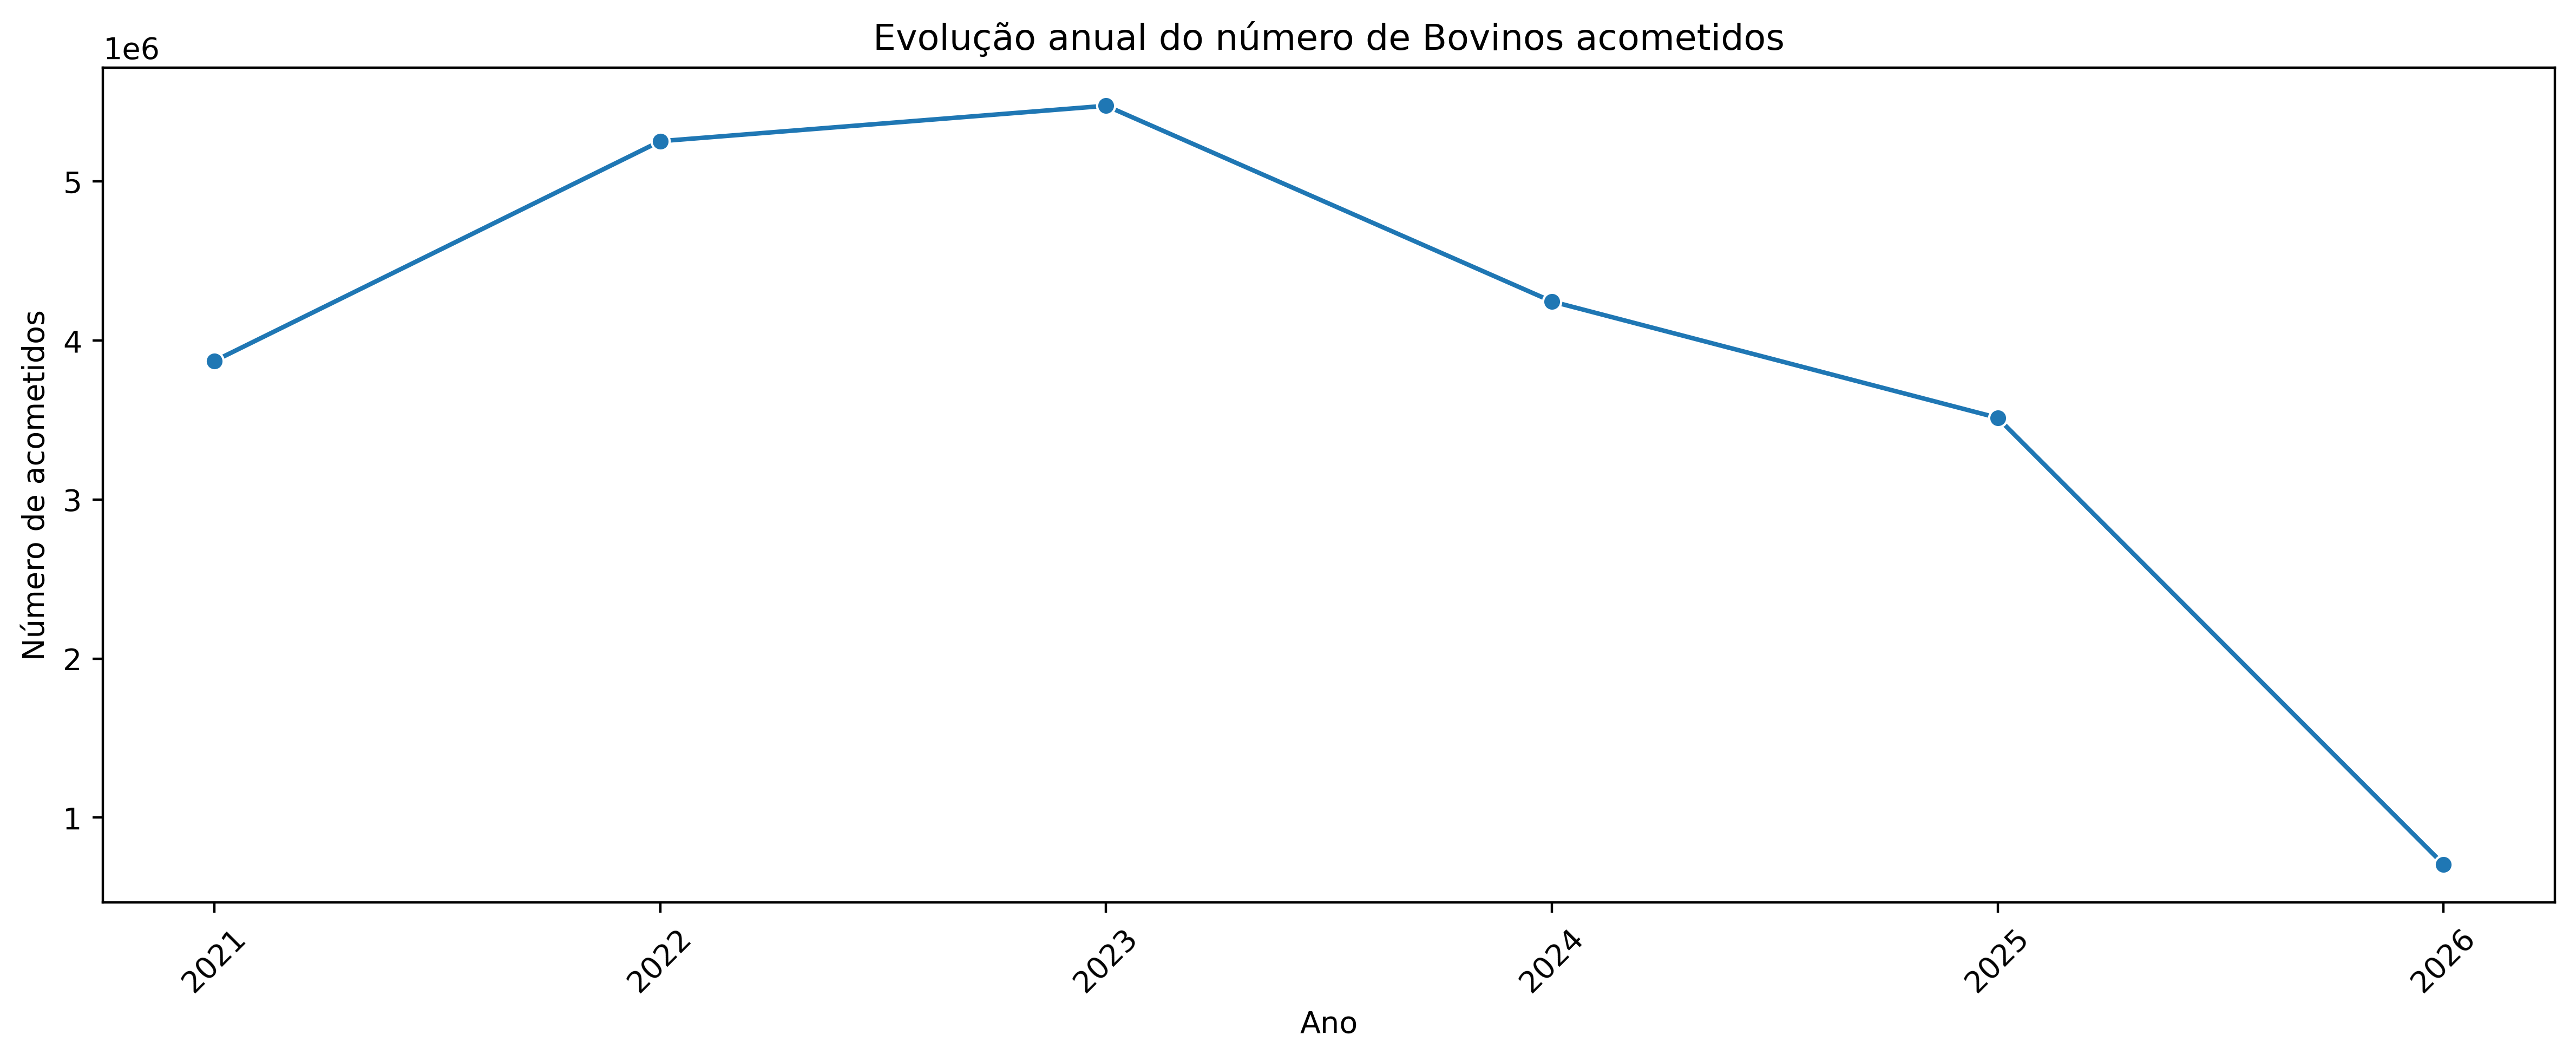

In [ ]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_suino_doenças.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Suínos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

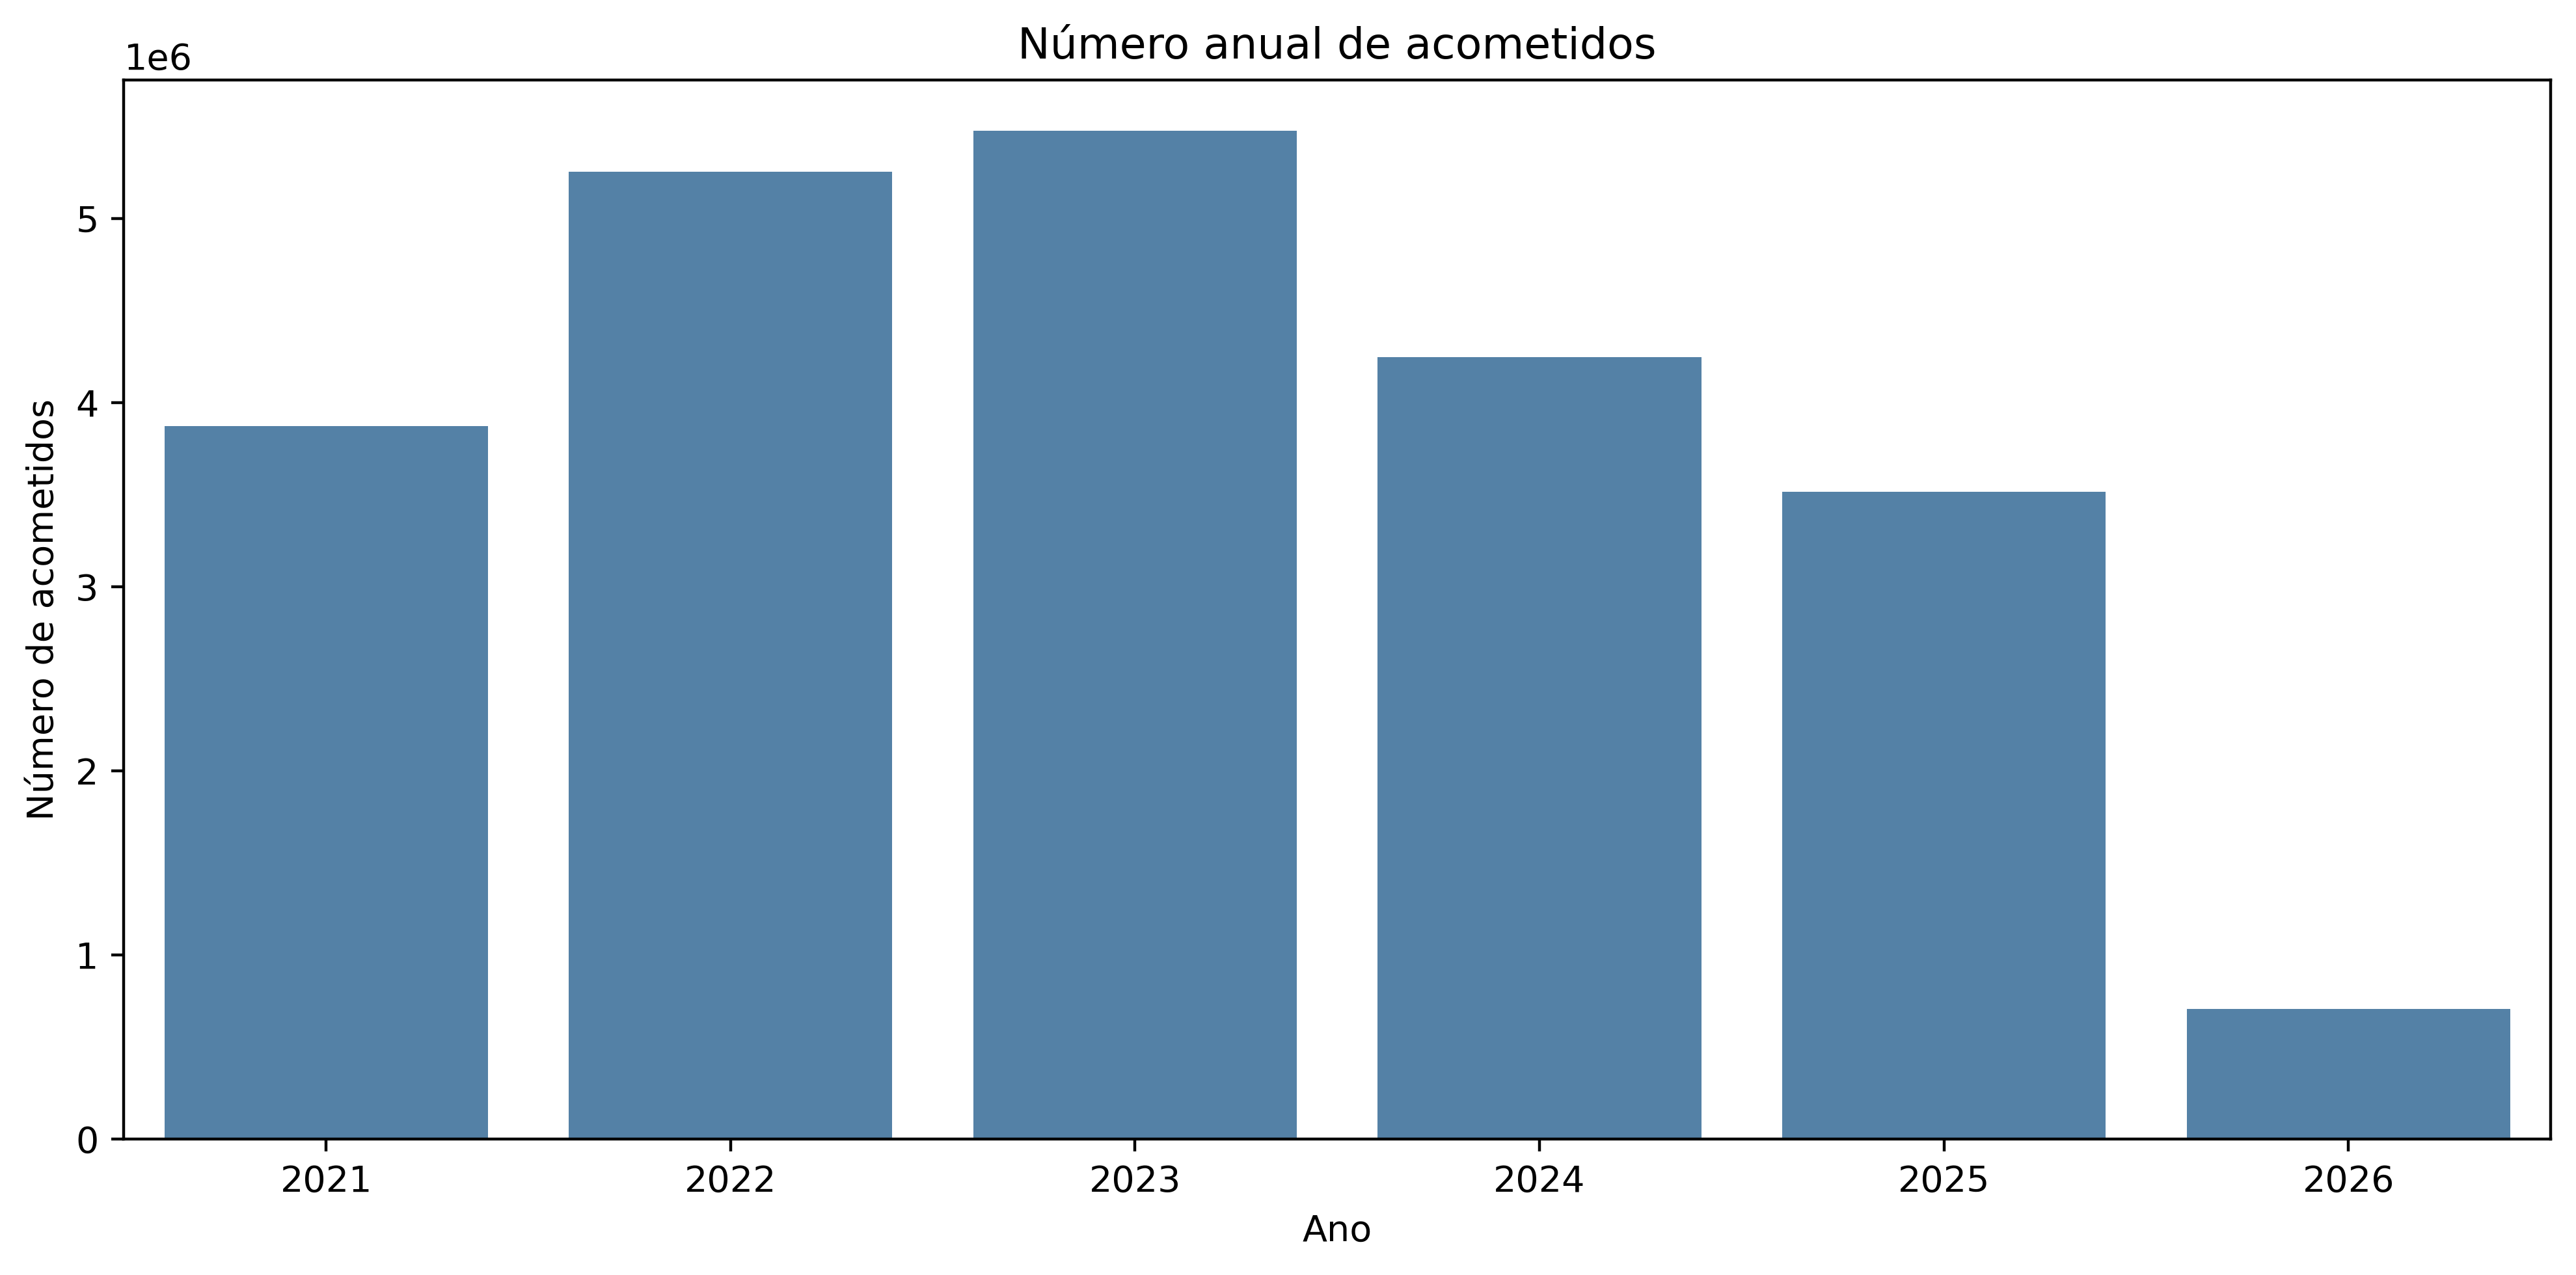

In [ ]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_suino_doenças.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

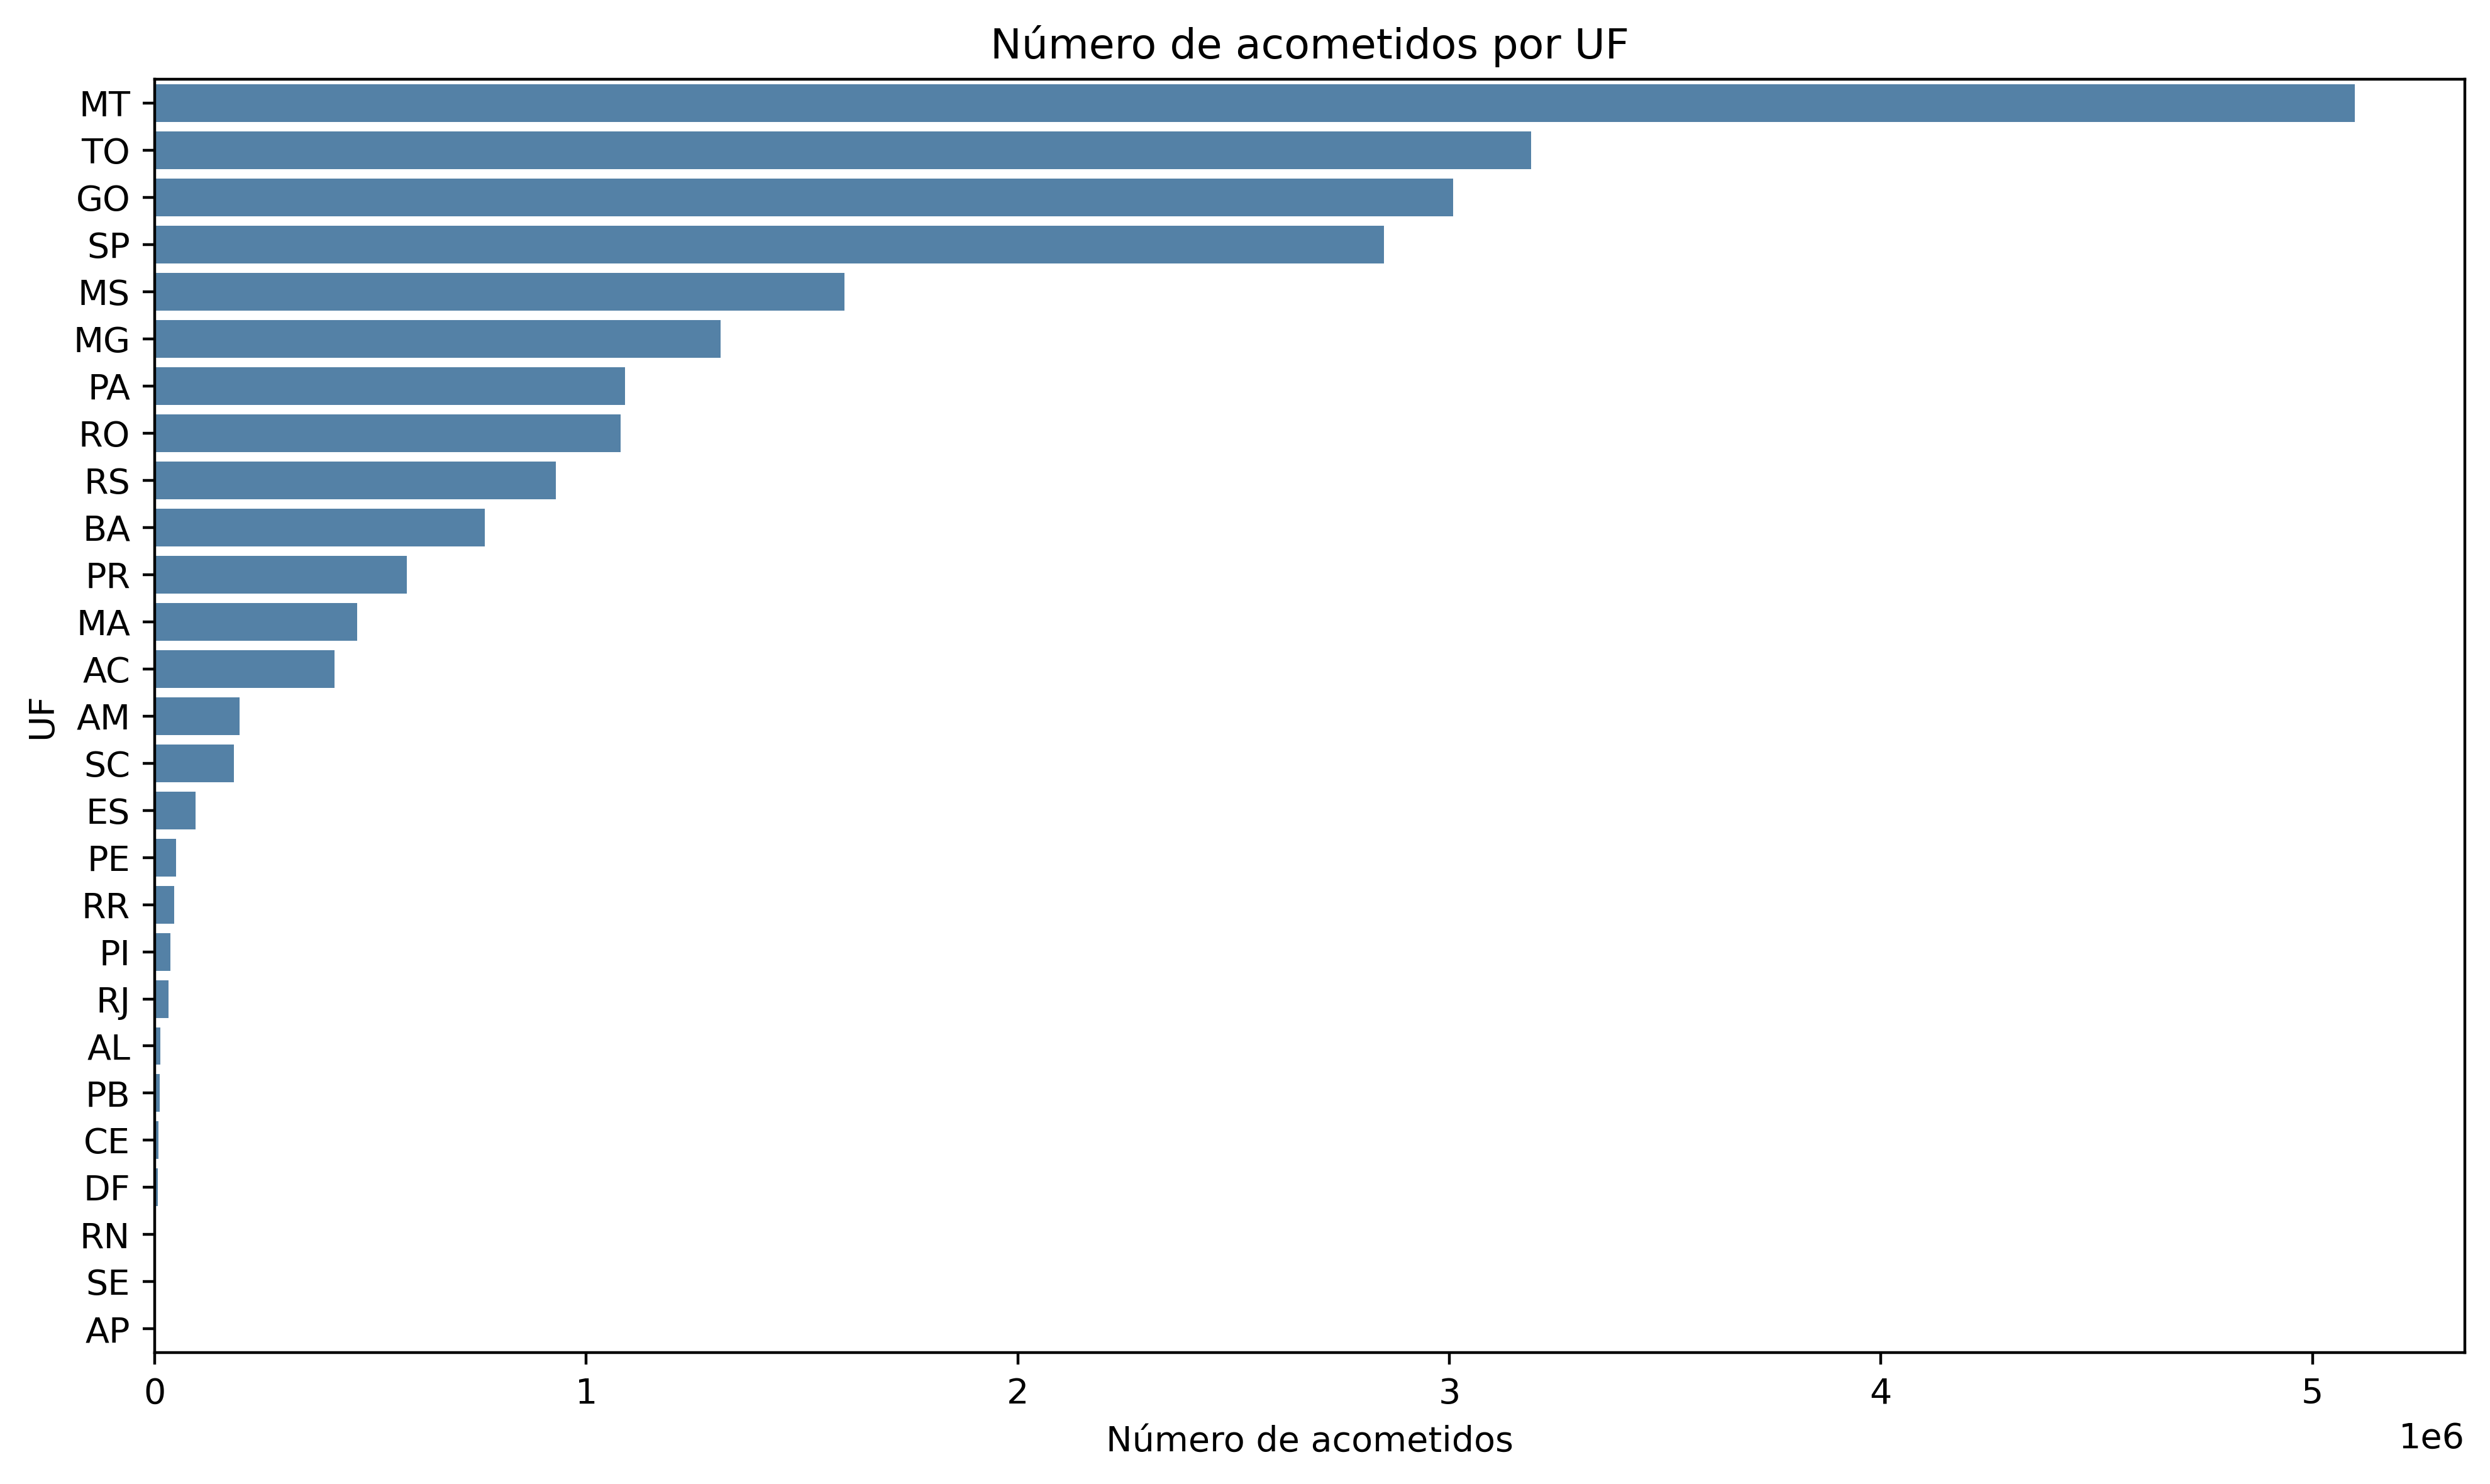

In [ ]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_suino_doenças.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [ ]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_suino_doenças,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value=0
)

tabela_uf_diagnostico

DIAGNOSTICO,aborto enzoótico das ovelhas (confirmado),aborto recente (fêmea),abscesso,abscesso (mamíferos),acrobustite,actinobacilose,actinobacilose (ruminantes),actinomicose (já notificado),actinomicose (notificação sif),adenite,...,tuberculose aviária (notificação sif),tuberculose calcificada,tuberculose caseosa,tuberculose miliar,tétano (notificação sif),uronefrose,variola,varíola bovina (já notificado),verminose,útero com feto(s)
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
AC,0,1,0,535,1,0,2,0,17,0,...,0,0,0,0,0,5,12,0,0,0
AL,0,0,0,166,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AM,0,0,3,239,0,0,0,0,3,0,...,0,0,0,0,0,13,0,0,0,0
AP,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BA,0,1,16,994,0,6,35,5,5,18,...,0,0,0,0,0,9,0,0,0,1
CE,0,0,0,30,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
DF,0,0,0,17,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,0,0
ES,0,0,45,980,0,0,7,2,5,0,...,0,0,0,0,0,0,0,0,0,0
GO,46,4,56,6913,26,0,27,51,375,9,...,0,0,0,0,0,34,0,0,3,14


In [ ]:
#Analisando o ranking por estado de procedência
ranking_uf = (
    df_suino_doenças.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
12,MT,5098015
26,TO,3189607
8,GO,3008558
25,SP,2848023
11,MS,1597684
10,MG,1310993
13,PA,1089909
20,RO,1080091
22,RS,929695
4,BA,765446


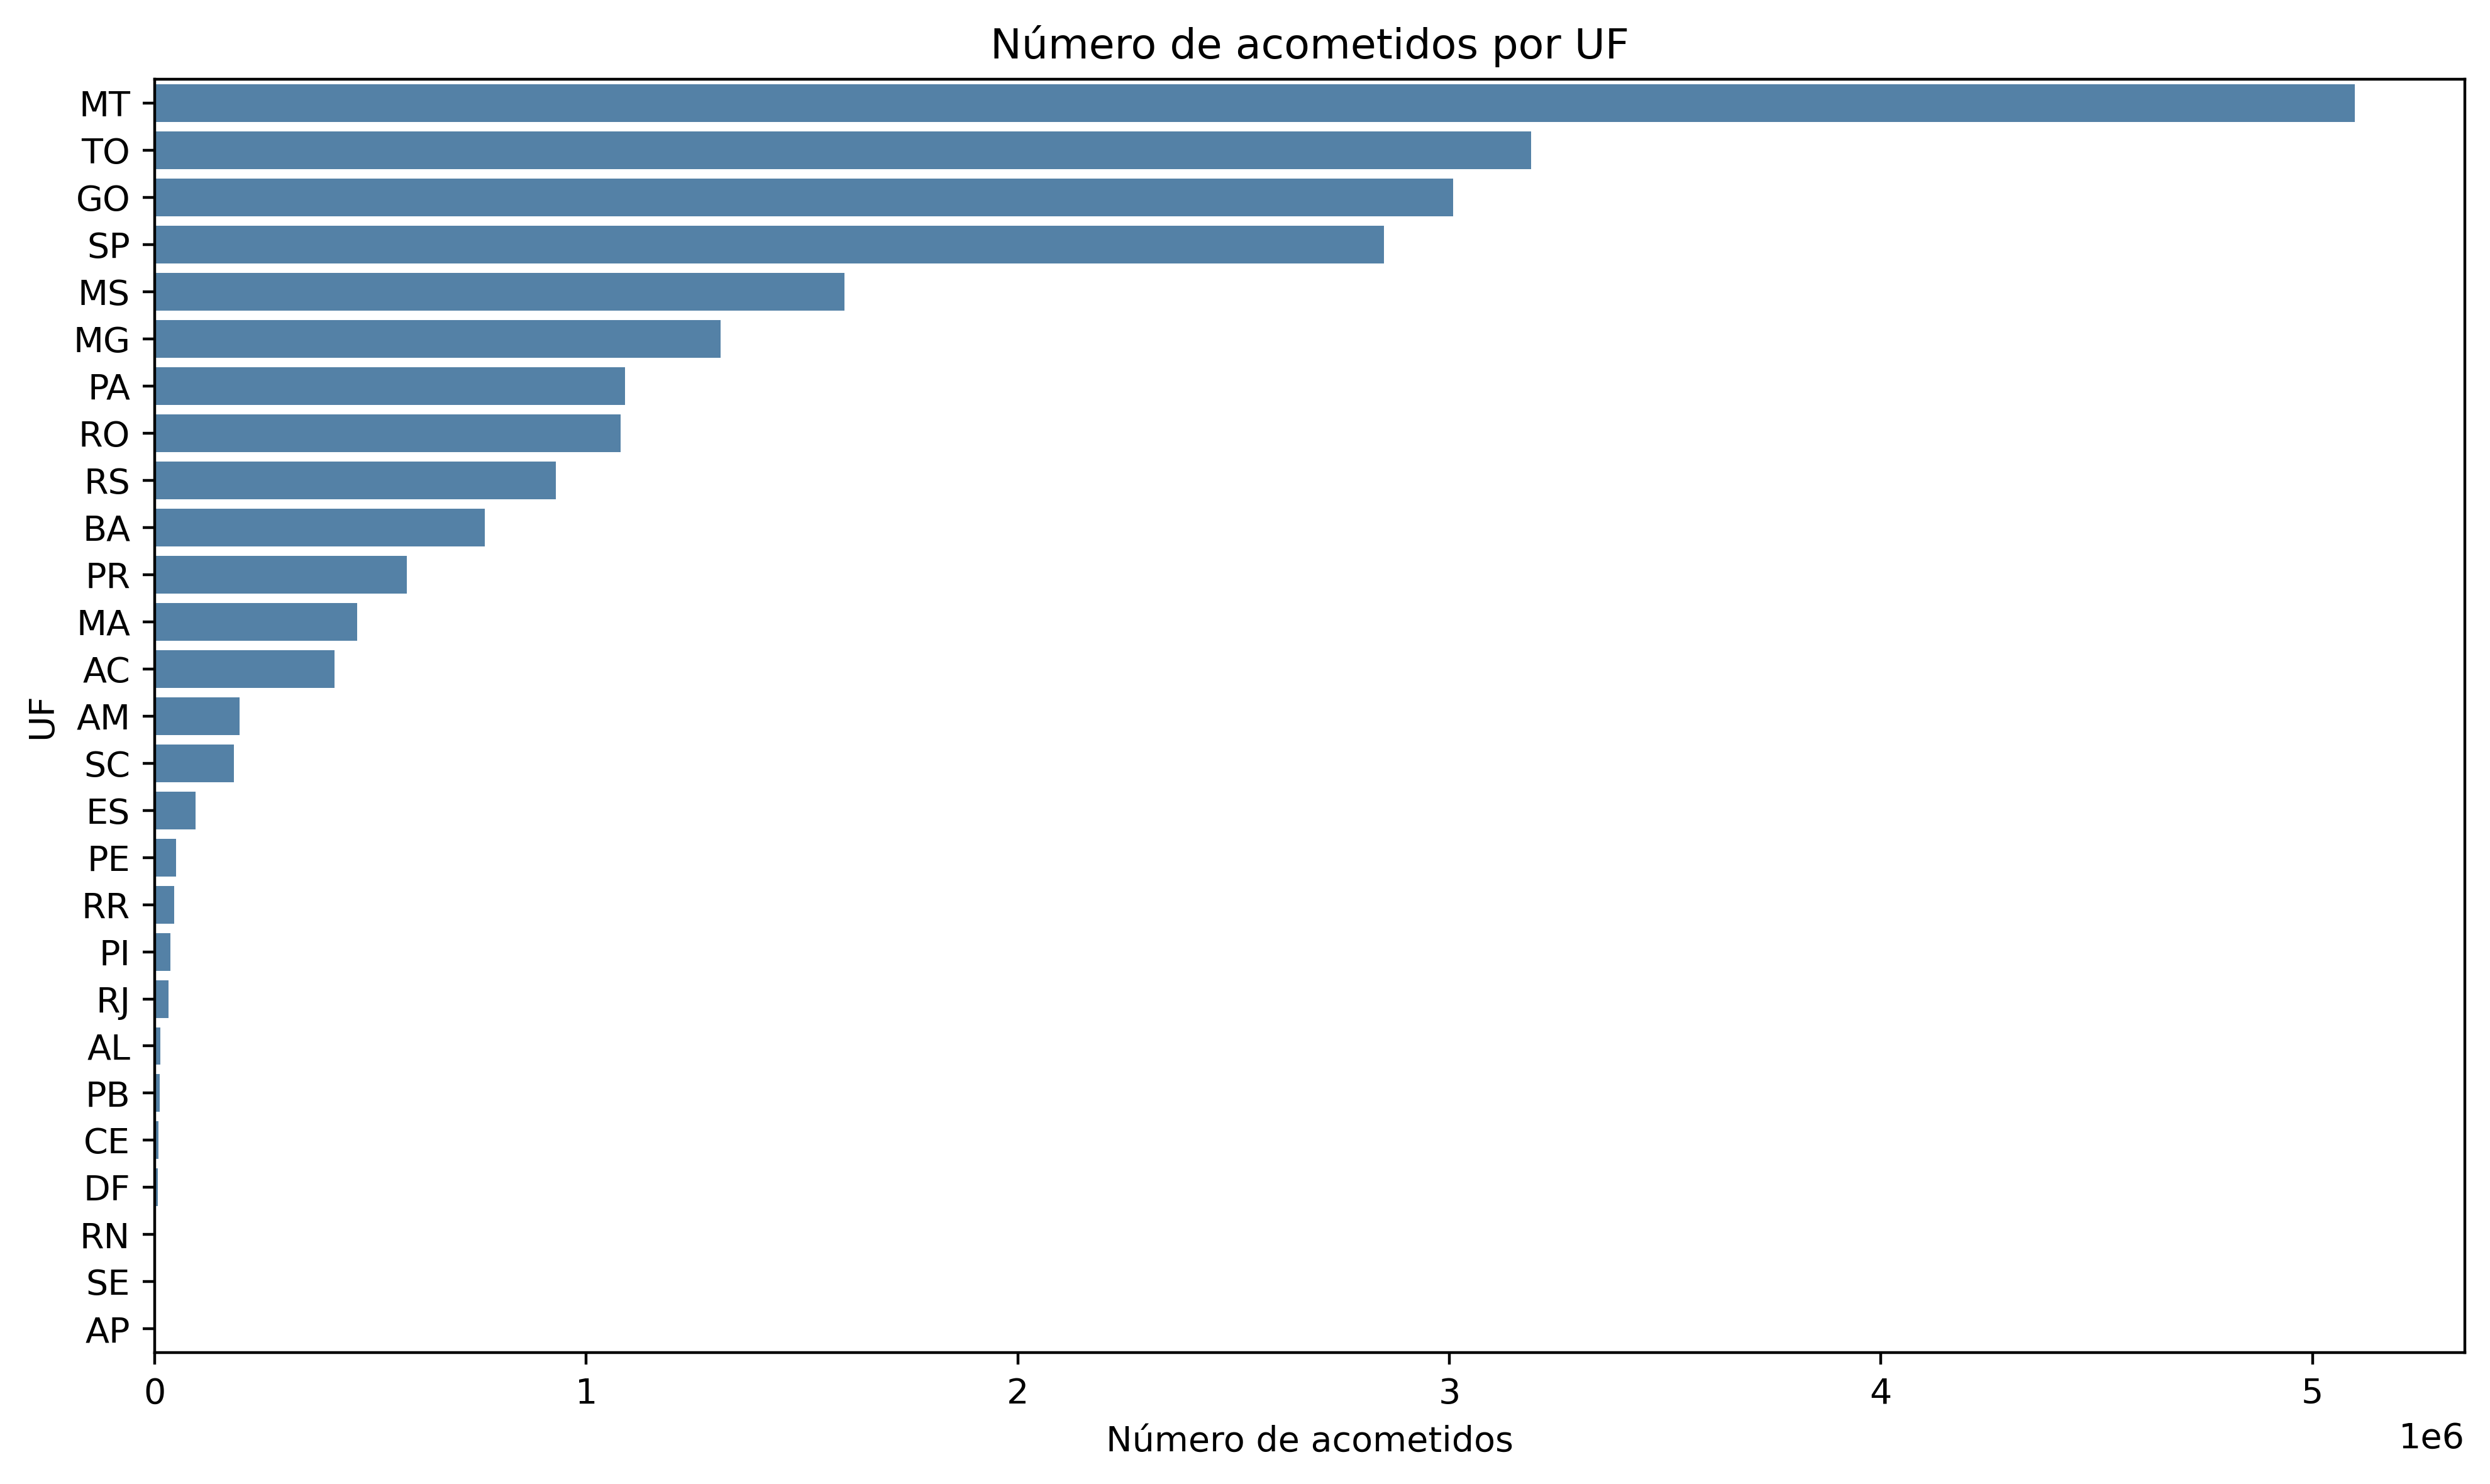

In [45]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [46]:
ranking_uf["percentual"] = (
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
12,MT,5098015,22
26,TO,3189607,14
8,GO,3008558,13
25,SP,2848023,12
11,MS,1597684,7
10,MG,1310993,6
13,PA,1089909,5
20,RO,1080091,5
22,RS,929695,4
4,BA,765446,3


In [ ]:
ranking_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
133,material especificado de risco (inutilização),14490928
63,contaminação gastrointestinal e biliar,2966929
18,alteração restrita,2756642
64,contaminação não gastrointestinal,671343
114,lesão inflamatória,407206
...,...,...
146,osteite,1
67,degeneracao gordurosa,1
142,necrobacilose,1
50,carnes sanguinolentas,1


In [48]:
ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
133,material especificado de risco (inutilização),14490928,63
63,contaminação gastrointestinal e biliar,2966929,13
18,alteração restrita,2756642,12
64,contaminação não gastrointestinal,671343,3
114,lesão inflamatória,407206,2
...,...,...,...
146,osteite,1,0
67,degeneracao gordurosa,1,0
142,necrobacilose,1,0
50,carnes sanguinolentas,1,0


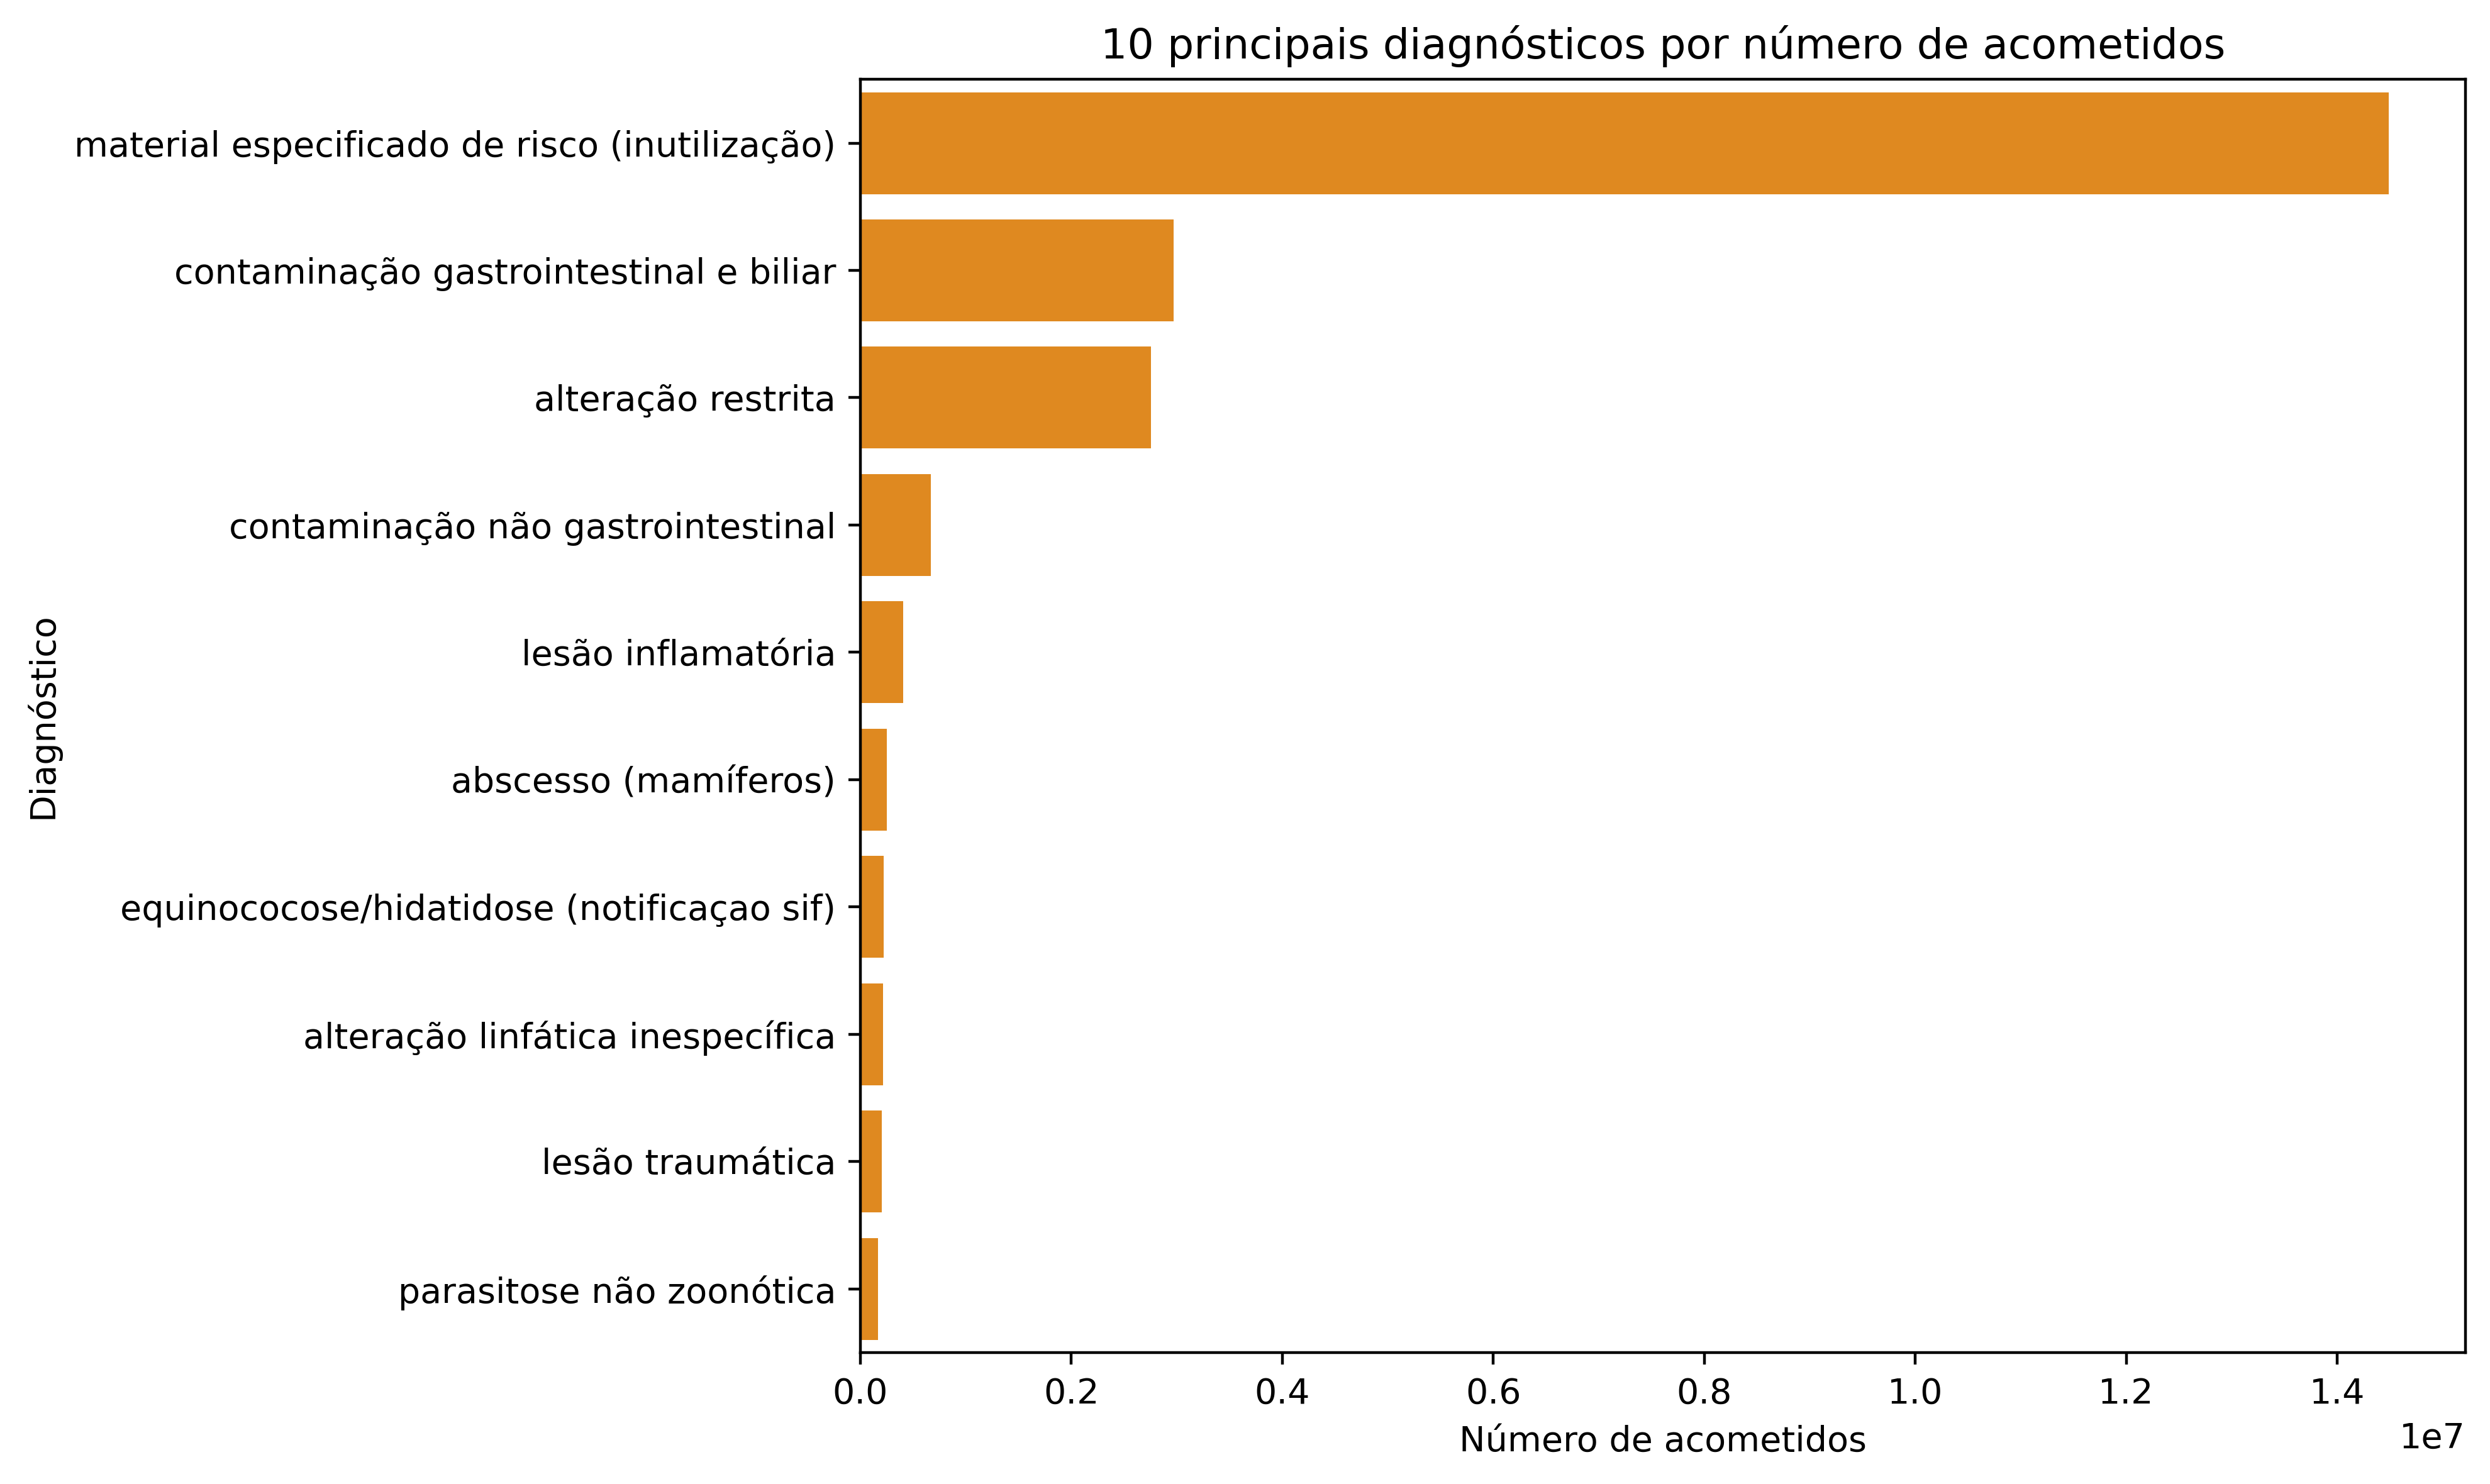

In [49]:
top10_diagnostico = ranking_diagnostico.head(10)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [ ]:
diagnostico_ano = (
    df_suino_doenças.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
121,2021,material especificado de risco (inutilização),2703127
57,2021,contaminação gastrointestinal e biliar,390723
16,2021,alteração restrita,349428
104,2021,lesão inflamatória,95116
58,2021,contaminação não gastrointestinal,49141
...,...,...,...
598,2026,footrot (notificação sif),1
602,2026,hipertermia (detectada no ante mortem),1
611,2026,leucose enzoótica bovina (já notificado),1
625,2026,prolapso (ante mortem),1


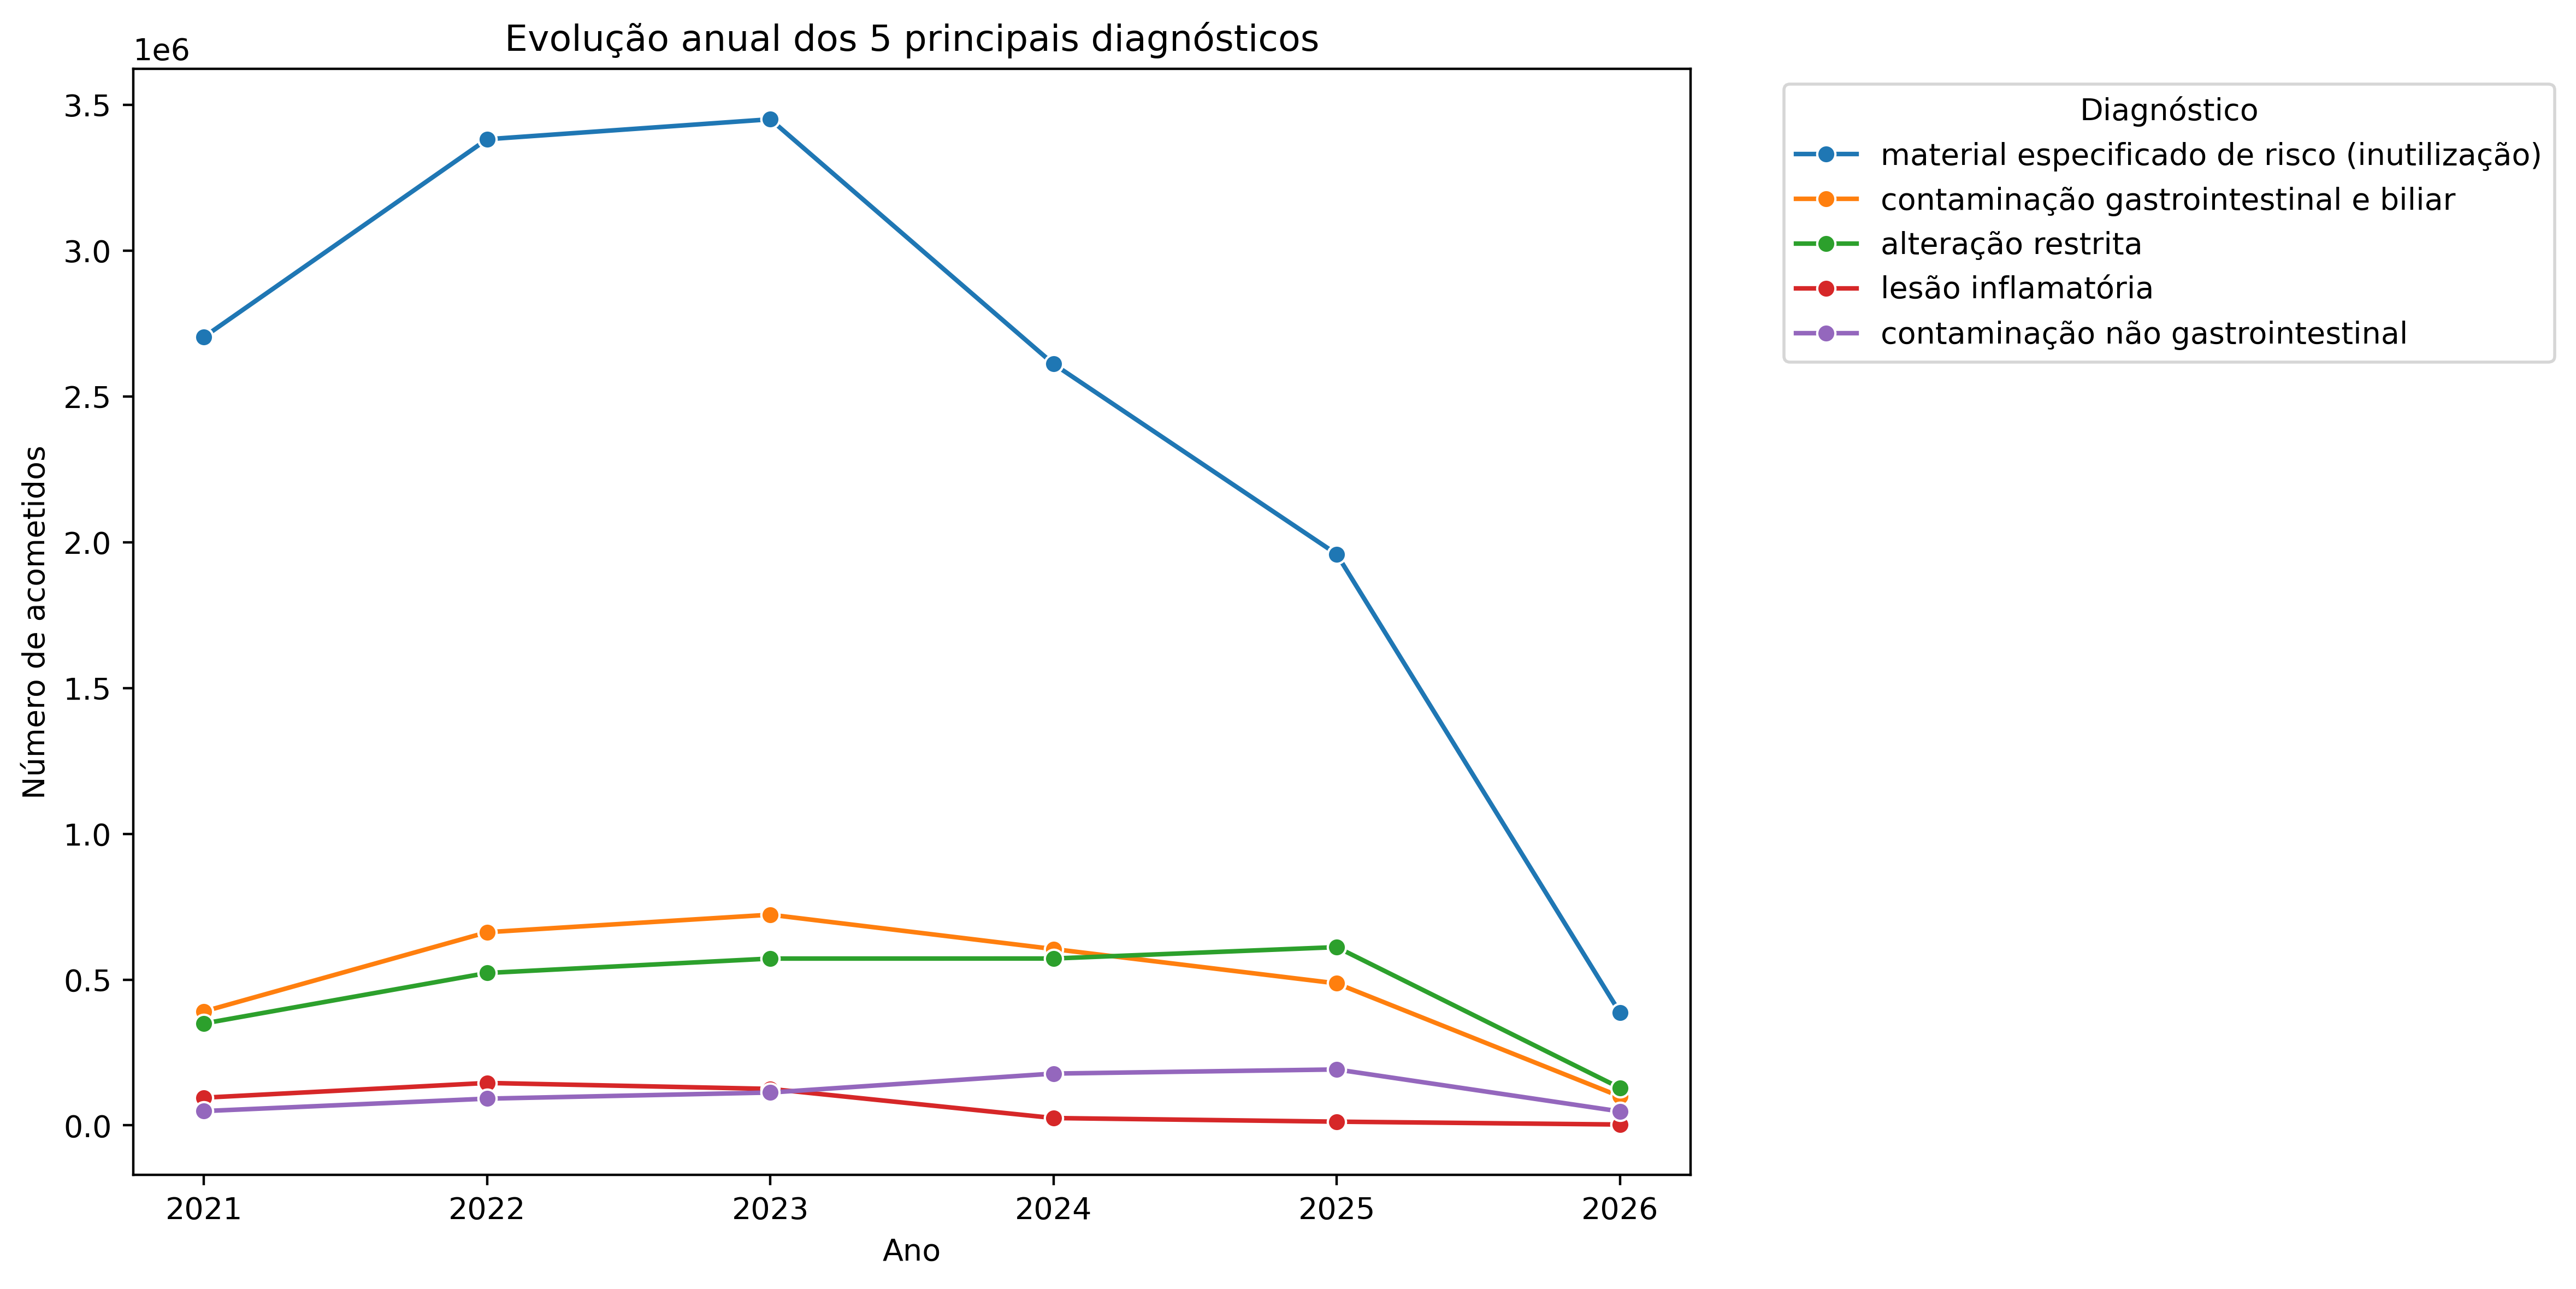

In [ ]:
top5_diag = (
    df_suino_doenças.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5 = diagnostico_ano[
    diagnostico_ano["DIAGNOSTICO"].isin(top5_diag)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [ ]:
media = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 685.04
Mediana: 6.00
Desvio Padrão: 3864.11
Variância: 14931368.29
Coeficiente de Variação: 564.07%


In [ ]:
assimetria = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 11.62
Curtose: 173.16


In [ ]:
minimo = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 88827
Amplitude: 88826
Q1: 1.0
Q3: 57.0
IQR: 56.0


In [ ]:
q1 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_suino_doenças[
    (df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
          MES_ANO UF_PROCEDENCIA ESPECIE  \
207753 2021-11-01             RS  Bovino   
225485 2025-11-01             RR  Bovino   
4271   2026-02-01             MT  Bovino   
236098 2021-05-01             MG  Bovino   
212858 2023-08-01             BA  Bovino   
...           ...            ...     ...   
205391 2023-12-01             MT  Bovino   
213854 2021-09-01             MT  Bovino   
55408  2023-09-01             MT  Bovino   
90361  2021-11-01             MT  Bovino   
80972  2021-12-01             MT  Bovino   

                                          DIAGNOSTICO  \
207753                       parasitose não zoonótica   
225485                       parasitose não zoonótica   
4271                               lesão inflamatória   
236098                síndrome hemorrágica (suspeito)   
212858                             lesão inflamatória   
...                                               ...   
205391  material especificado de risco (inutilizaç

In [ ]:
desc_por_uf = (
      df_suino_doenças.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf


,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
MT,3142,5098015,1623,3,8771,1,88827
TO,1839,3189607,1734,39,3482,1,26795
GO,2307,3008558,1304,6,6188,1,60252
SP,2244,2848023,1269,10,5077,1,45077
MS,2227,1597684,717,3,3591,1,36112
MG,2634,1310993,498,3,2547,1,30669
PA,2365,1089909,461,3,2107,1,21210
RO,1894,1080091,570,3,2509,1,22299
RS,2241,929695,415,3,1420,1,12779


In [ ]:
desc_por_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
material especificado de risco (inutilização),1399,14490928,10358,4832,15252,1,88827
contaminação gastrointestinal e biliar,1409,2966929,2106,681,3399,1,21904
alteração restrita,1411,2756642,1954,1026,2535,1,14992
contaminação não gastrointestinal,1243,671343,540,129,1129,1,10995
lesão inflamatória,1214,407206,335,70,813,1,6568
...,...,...,...,...,...,...,...
osteite,1,1,1,1,NaN,1,1
degeneracao gordurosa,1,1,1,1,NaN,1,1
necrobacilose,1,1,1,1,NaN,1,1


In [ ]:
ranking_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico["percentual_acumulado"] = ranking_diagnostico["percentual"].cumsum()

ranking_diagnostico


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
133,material especificado de risco (inutilização),14490928,63,63
63,contaminação gastrointestinal e biliar,2966929,13,76
18,alteração restrita,2756642,12,88
64,contaminação não gastrointestinal,671343,3,91
114,lesão inflamatória,407206,2,92
...,...,...,...,...
146,osteite,1,0,100
67,degeneracao gordurosa,1,0,100
142,necrobacilose,1,0,100
50,carnes sanguinolentas,1,0,100


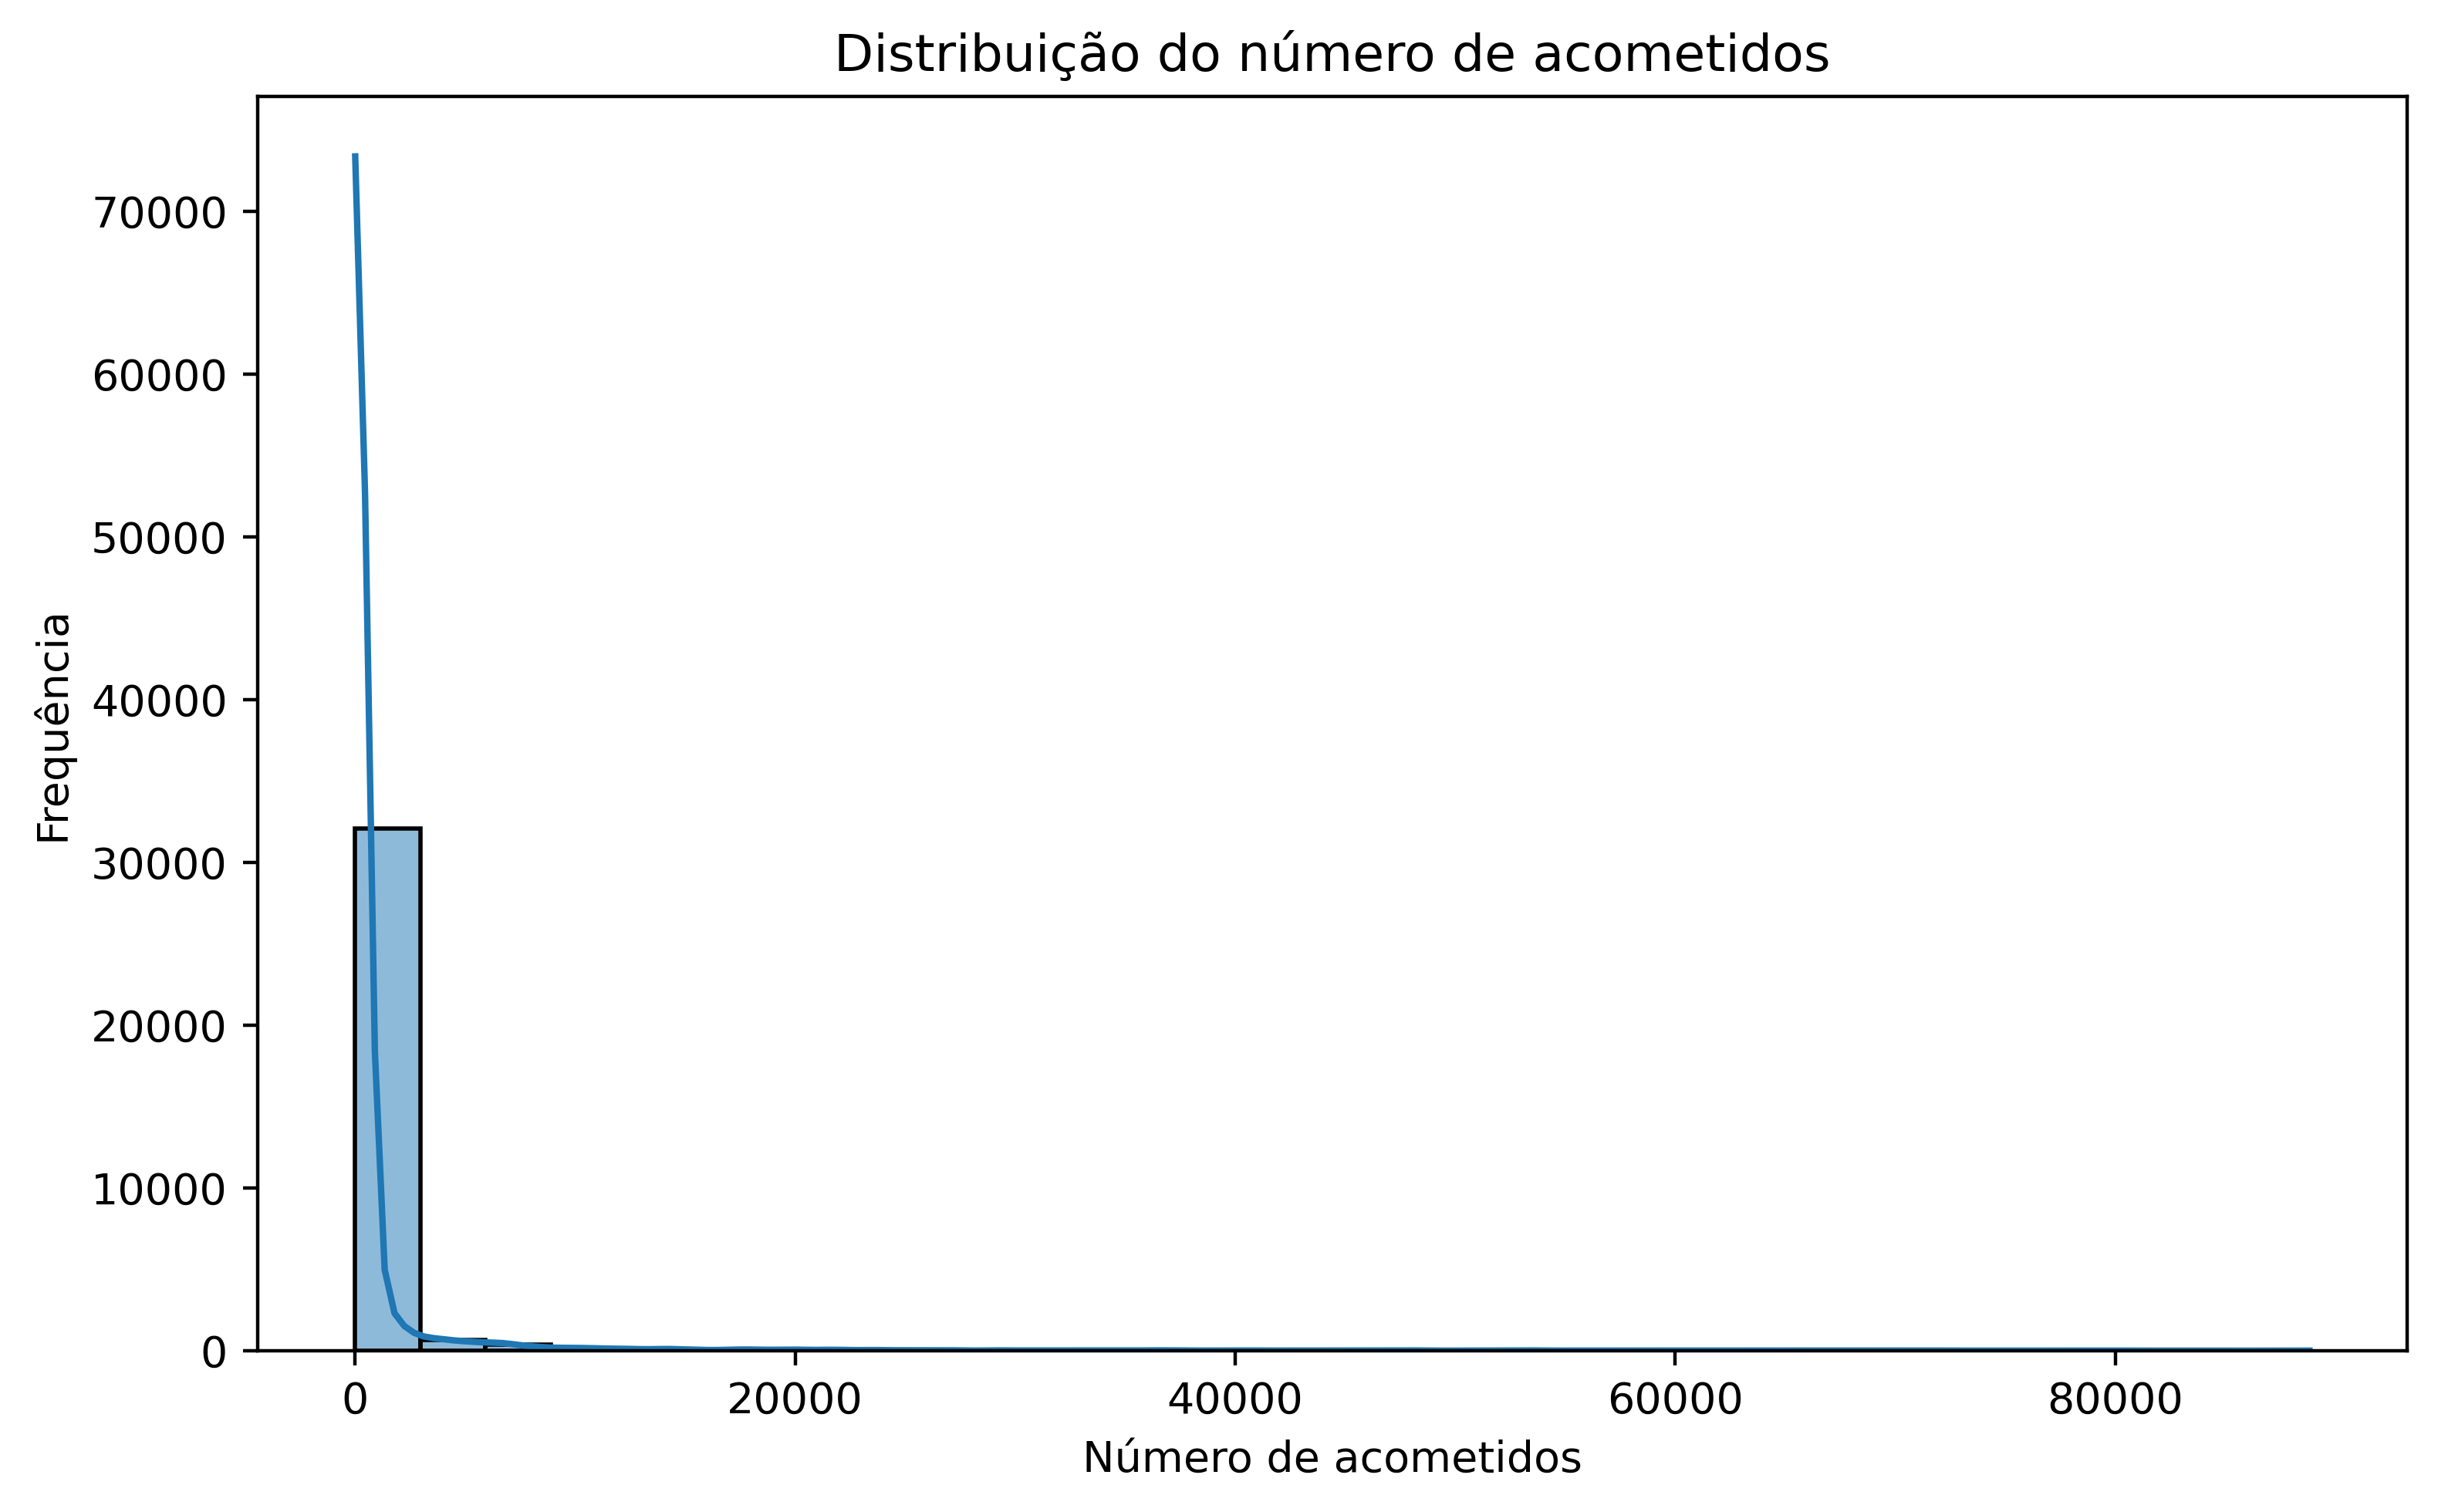

In [ ]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_suino_doenças,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


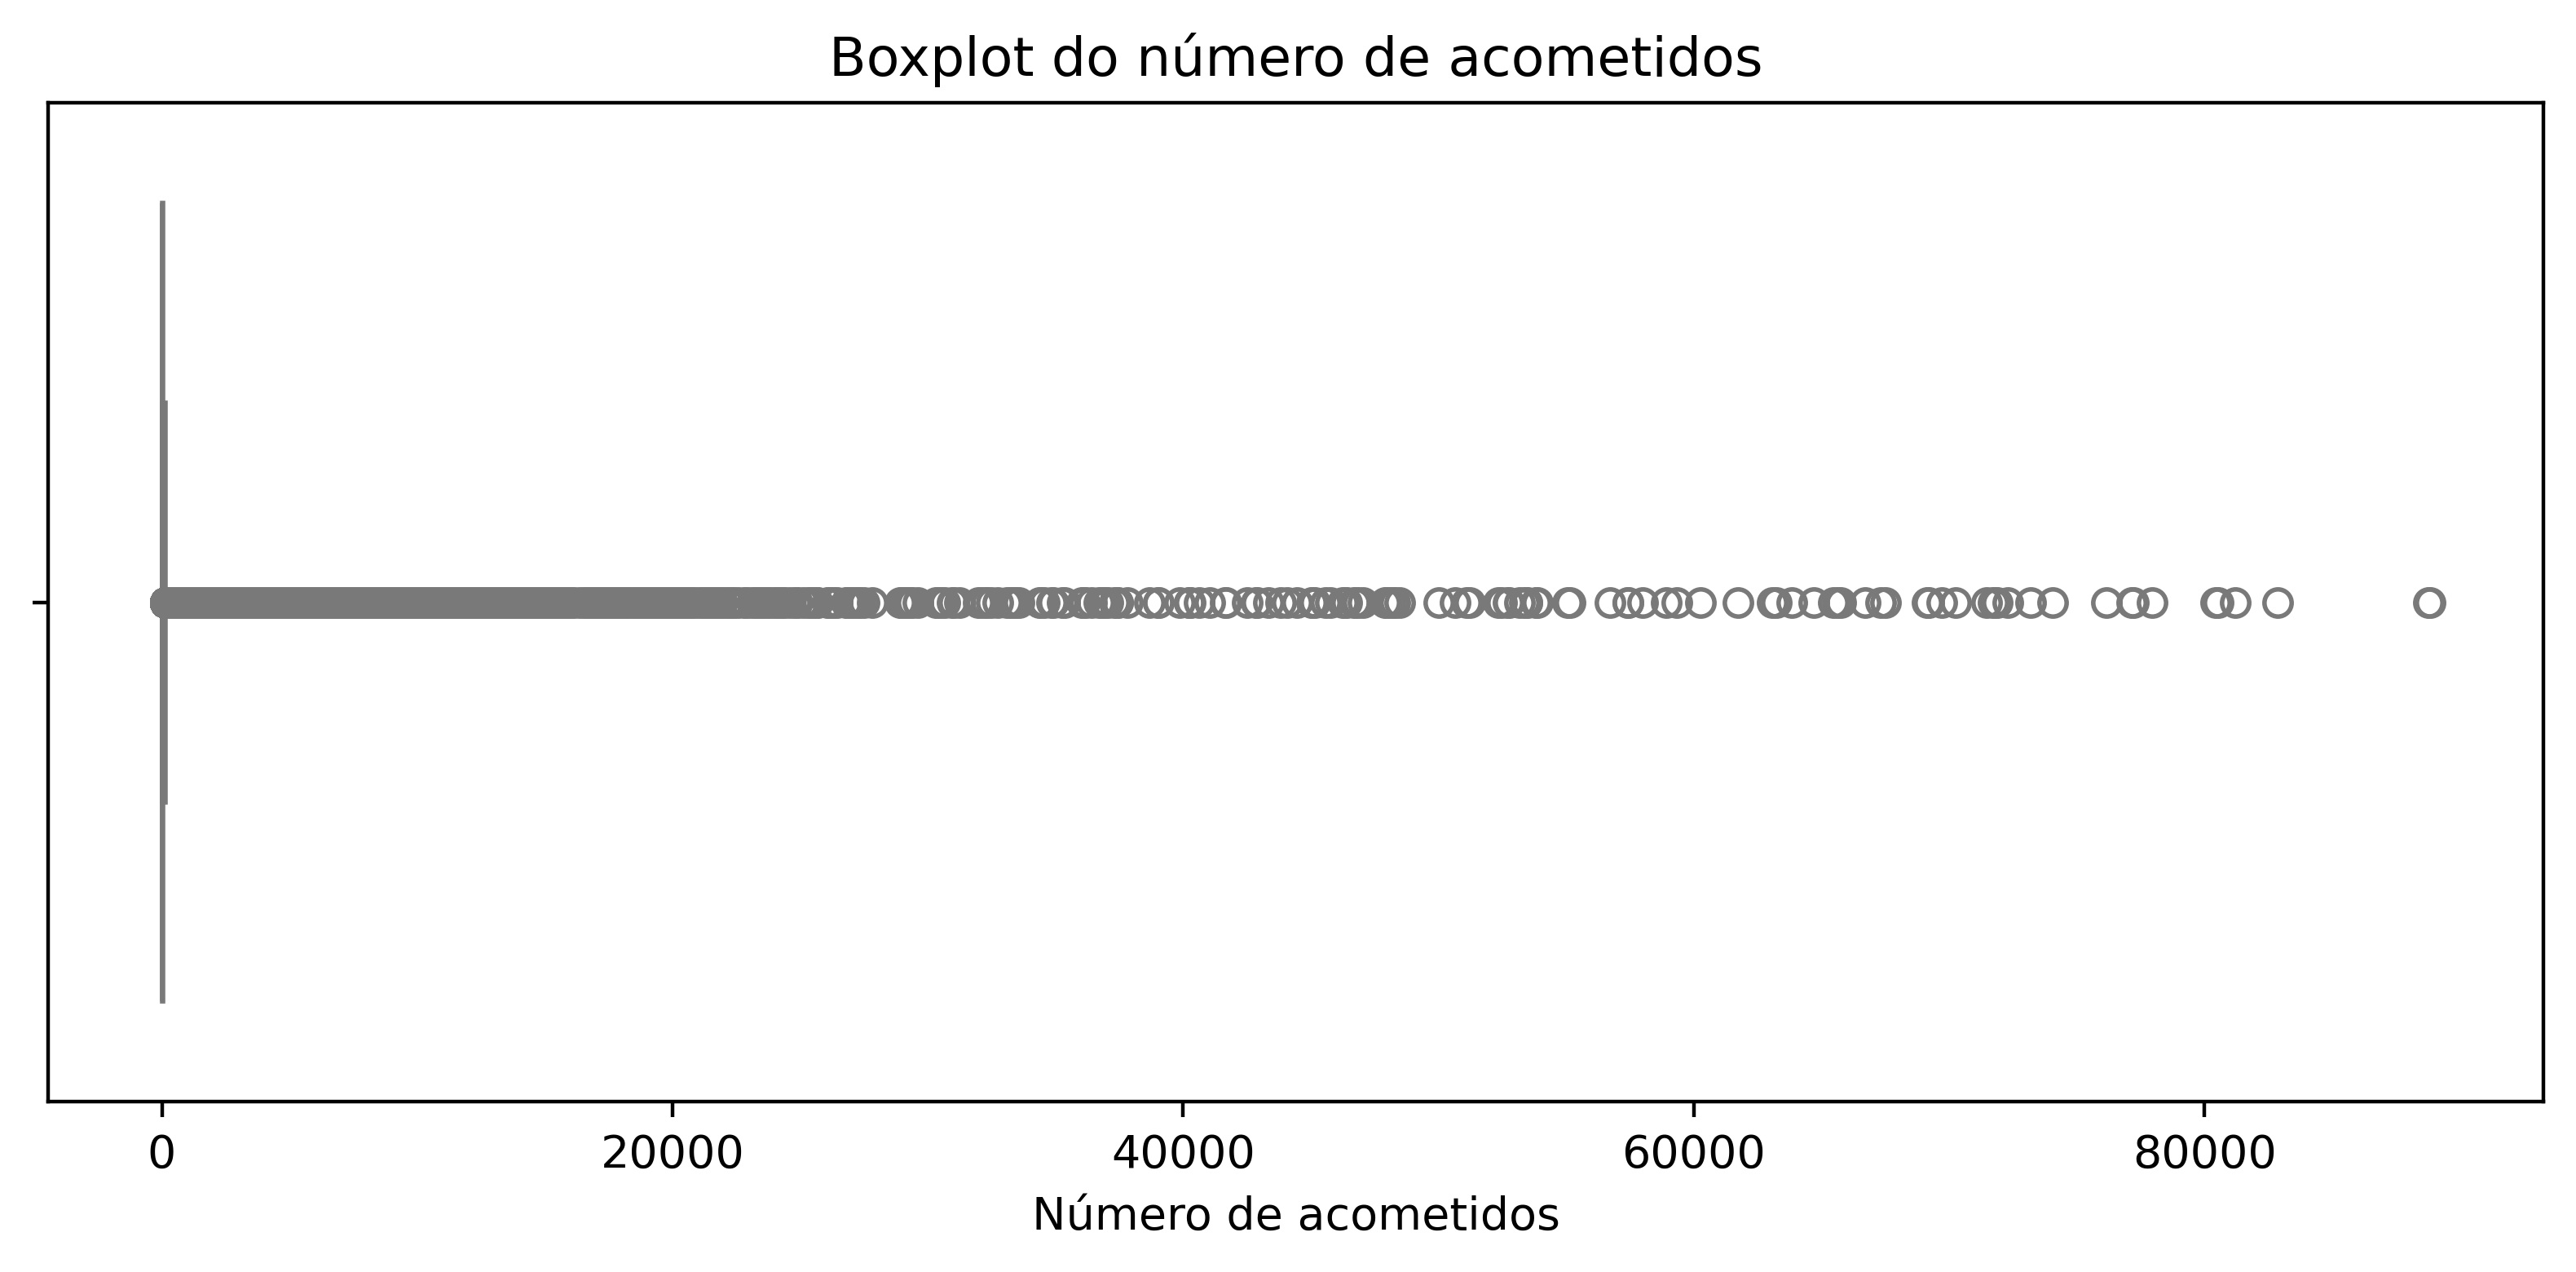

In [ ]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_suino_doenças,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()
